# Chapter-10: Fundamentals Of LangGraph

# <font color="#800000">Introduction To LangGraph</font>

## <font color="#3366FF">Getting Started With LangGraph Example</font>

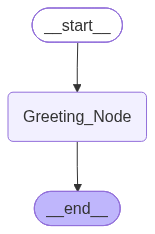

In [1]:
from langgraph.graph import StateGraph
from IPython.display import Image, display

## Function for creating greetings with name
def fn_greeting(name:str):
    return f"Hello {name}"

## Initialize a StateGraph object for building a graph
graph_builder = StateGraph(str)

## Add a node to the graph
graph_builder.add_node("Greeting_Node", fn_greeting)

## Set entry point of graph execution
graph_builder.set_entry_point("Greeting_Node")

## Compile Graph
graph = graph_builder.compile()

## Visualize the graph
display(Image(graph.get_graph().draw_mermaid_png()))


In [2]:
## Invoke Graph
graph.invoke("Ankur")


'Hello Ankur'

# <font color="#800000">Core Building Blocks Of LangGraph</font>

## <font color="#3366FF">Nodes</font>

### Add Node Method

#### Example

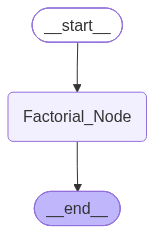

Factorial result is 24


In [3]:
from langgraph.graph import StateGraph
from IPython.display import Image, display

## Define factorial function
def fn_factorial(n: int):
    result=1
    for i in range(1, n + 1):
        result *= i
    return result

## Initialize a StateGraph object for integer input/output
graph_builder = StateGraph(int)

## Add a node that performs factorial calculation
graph_builder.add_node("Factorial_Node", fn_factorial)

## Set the entry point of the graph
graph_builder.set_entry_point("Factorial_Node")

## Compile graph
graph = graph_builder.compile()

## Visualize the graph structure
display(Image(graph.get_graph().draw_mermaid_png()))

## Invoke graph
output = graph.invoke(4)

## Print Output
print("Factorial result is", output)


### Example Of LLM Node

/Users/ankur/Desktop/Langchain_Review/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


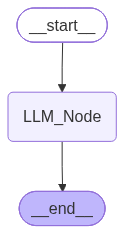

A black hole is a region of spacetime with gravity so strong that nothing, not even light, can escape its event horizon.


In [4]:
import os
from dotenv import load_dotenv
from langgraph.graph import StateGraph
from langchain_openai import ChatOpenAI
from IPython.display import Image, display

## Loading OpenAI API key from env file into an environment variable
load_dotenv()
os.environ["OPENAI_API_KEY"] = os.getenv('OPENAI_API_KEY')


## Define a function that calls LLM
def call_llm(prompt: str):
    
    ## Initialize ChatOpenAI LLM
    llm = ChatOpenAI(model="gpt-5-mini", temperature=0)
    
    ## Invoke LLM with input prompt
    response = llm.invoke(prompt)
    
    ## Return string content from response
    return response.content


## Initialize a StateGraph (input/output type = str)
graph_builder = StateGraph(str)

## Add node for LLM call
graph_builder.add_node("LLM_Node", call_llm)

## Set entry point
graph_builder.set_entry_point("LLM_Node")

## Compile graph
graph = graph_builder.compile()

## Visualize Graph
display(Image(graph.get_graph().draw_mermaid_png()))

## Invoke graph
output = graph.invoke("Explain concept of Black Hole in one line.")

## Print output
print(output)


## <font color="#3366FF">Normal Edges</font>

### Add Edge Method

### Example

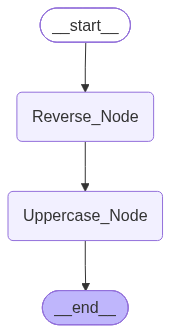

Final Output: YSAE SI HPARGGNAL


In [5]:
from langgraph.graph import StateGraph, START, END
from IPython.display import Image, display

## Define Node Functions
def reverse_string(text: str):
    """Node 1: Reverse the input string."""
    return text[::-1]

def to_uppercase(text: str):
    """Node 2: Convert text to uppercase."""
    return text.upper()

## Initialize StateGraph with state variable as string
graph_builder = StateGraph(str)

## Add Nodes
graph_builder.add_node("Reverse_Node", reverse_string)
graph_builder.add_node("Uppercase_Node", to_uppercase)

## Connect START to Reverse_Node with Edge
graph_builder.add_edge(START, "Reverse_Node")

## Connect Reverse_Node to Uppercase_Node with Edge
graph_builder.add_edge("Reverse_Node", "Uppercase_Node")

## Connect Uppercase_Node to END with Edge
graph_builder.add_edge("Uppercase_Node", END)

## Compile Graph
graph = graph_builder.compile()

## Visualize Graph
display(Image(graph.get_graph().draw_mermaid_png()))

## Invoke Graph
output = graph.invoke("LangGraph is easy")

## Print Output
print("Final Output:", output)


## <font color="#3366FF">Conditional Edges</font>

### Add Conditional Edges Method

In [6]:
from langgraph.graph import StateGraph, START, END

## Define Node Functions
def add_ten(number: int) -> int:
    """Node 1: Add 10 to the number."""
    result = number + 10
    print(f"Add_Node: {number} + 10 = {result}")
    return result

def multiply_by_two(number: int) -> int:
    """Node 2: Multiply the number by 2."""
    result = number * 2
    print(f"Multiply_Node: {number} * 2 = {result}")
    return result

def subtract_five(number: int) -> int:
    """Node 3: Subtract 5 from the number."""
    result = number - 5
    print(f"Subtract_Node: {number} - 5 = {result}")
    return result

## Define Conditional Function
def route_based_on_value(number: int) -> str:
    """Routing function: Choose path based on number value."""
    if number > 50:
        print(f"Routing: {number} > 50, going to multiply path")
        return "multiply"  ## Return the key, not the node name
    else:
        print(f"Routing: {number} <= 50, going to subtract path")
        return "subtract"  ## Return the key, not the node name

## Initialize StateGraph with state variable as int
graph_builder = StateGraph(int)

## Add Nodes
graph_builder.add_node("Add_Node", add_ten)
graph_builder.add_node("Multiply_Node", multiply_by_two)
graph_builder.add_node("Subtract_Node", subtract_five)

## Connect START to Add_Node with normal edge
graph_builder.add_edge(START, "Add_Node")

## Connect Add_Node with CONDITIONAL EDGE
graph_builder.add_conditional_edges(
    "Add_Node",  ## Source node
    route_based_on_value,  # Routing function
    {
        "multiply": "Multiply_Node",  ## Map route key to node name
        "subtract": "Subtract_Node"   ## Map route key to node name
    }
)

## Connect both paths to END
graph_builder.add_edge("Multiply_Node", END)
graph_builder.add_edge("Subtract_Node", END)

## Compile Graph
graph = graph_builder.compile()


In [7]:
## Test with different inputs
print("\n" + "="*50)
print("Test 1 - Input: 45")
print("="*50)
output1 = graph.invoke(45)
print(f"Final Output: {output1}\n")

print("="*50)
print("Test 2 - Input: 20")
print("="*50)
output2 = graph.invoke(20)
print(f"Final Output: {output2}")



Test 1 - Input: 45
Add_Node: 45 + 10 = 55
Routing: 55 > 50, going to multiply path
Multiply_Node: 55 * 2 = 110
Final Output: 110

Test 2 - Input: 20
Add_Node: 20 + 10 = 30
Routing: 30 <= 50, going to subtract path
Subtract_Node: 30 - 5 = 25
Final Output: 25


## <font color="#3366FF">State</font>

### State Schema

#### Example of TypedDict Schema

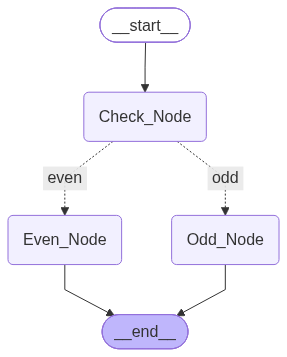

In [8]:
from typing import TypedDict
from langgraph.graph import StateGraph, START, END
from IPython.display import Image, display


## Define TypedDict for graph state
class NumberState(TypedDict):
    num: int
    num_type: str
    output: str


## Node function to check if number is even or odd
def check_even_odd(state: NumberState):
    number = state["num"]
    
    ## Return state by assigning “even” or “odd” to num_type
    state["num_type"] = "even" if number % 2 == 0 else "odd"
    return state


## Node function for handling even numbers
def handle_even(state: NumberState):
    state["output"] = f"{state['num']} is even"
    return state


## Node function for handling odd numbers
def handle_odd(state: NumberState):
    state["output"] = f"{state['num']} is odd"
    return state


## Initialize the StateGraph with TypedDict
graph_builder = StateGraph(NumberState)

## Add nodes
graph_builder.add_node("Check_Node", check_even_odd)
graph_builder.add_node("Even_Node", handle_even)
graph_builder.add_node("Odd_Node", handle_odd)

## Add edge from START to Check_Node
graph_builder.add_edge(START, "Check_Node")

## Conditional edge from Check_Node
graph_builder.add_conditional_edges(
    "Check_Node",
    lambda state: state["num_type"],
    {
        "even": "Even_Node",
        "odd": "Odd_Node"
    }
)

## Add edge from Even_Node to END
graph_builder.add_edge("Even_Node", END)

## Add edge from Odd_Node to END
graph_builder.add_edge("Odd_Node", END)

## Compile the graph
graph = graph_builder.compile()

## Visualize Graph
display(Image(graph.get_graph().draw_mermaid_png()))


In [9]:
## Scenario 1
print("\n" + "="*50)
print("Scenario 1: Even Input")
print("="*50)
print(graph.invoke({"num": 10}))

## Scenario 2
print("\n" + "="*50)
print("Scenario 2: Odd Input")
print("="*50)
print(graph.invoke({"num": 7}))



Scenario 1: Even Input
{'num': 10, 'num_type': 'even', 'output': '10 is even'}

Scenario 2: Odd Input
{'num': 7, 'num_type': 'odd', 'output': '7 is odd'}


#### Example of Pydantic Schema

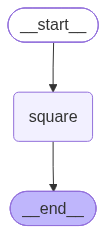

In [10]:
from pydantic import BaseModel, Field, ValidationError
from typing import Optional
from langgraph.graph import StateGraph 
from IPython.display import Image, display

## Define Pydantic Model for graph state
class GraphState(BaseModel):
    input: int = Field(ge=1, le=10)
    output: Optional[int] = Field(default=None, ge=1, le=10)

## Node 1 - Calculates square of the input
def calc_square(state: GraphState) -> GraphState:  
    state.output = state.input * state.input
    return state

## Initialize a StateGraph object for integer input/output
graph_builder = StateGraph(GraphState)

## Add a node that performs square calculation
graph_builder.add_node("square", calc_square)

## Set the entry point of the graph
graph_builder.set_entry_point("square")

## Compile graph
graph = graph_builder.compile()

## Visualize the graph structure
display(Image(graph.get_graph().draw_mermaid_png()))


In [11]:
## Scenario 1
print("\n" + "="*50)
print("Scenario 1: Input Less Than 10")
print("="*50)
try: 
    print(graph.invoke({"input": 3}))
except ValidationError as e:
    print(f"Error: {e}")

## Scenario 2
print("\n" + "="*50)
print("Scenario 2: Input More Than 10")
print("="*50)
try: 
    print(graph.invoke({"input": 15}))
except ValidationError as e:
    print(f"Error: {e}")

## Scenario 3
print("\n" + "="*50)
print("Scenario 3: Output More Than 10")
print("="*50)
try: 
    print(graph.invoke({"input": 8}))
except ValidationError as e:
    print(f"Error: {e}")



Scenario 1: Input Less Than 10
{'input': 3, 'output': 9}

Scenario 2: Input More Than 10
Error: 1 validation error for GraphState
input
  Input should be less than or equal to 10 [type=less_than_equal, input_value=15, input_type=int]
    For further information visit https://errors.pydantic.dev/2.13/v/less_than_equal

Scenario 3: Output More Than 10
{'input': 8, 'output': 64}


### Input and Output State Schemas

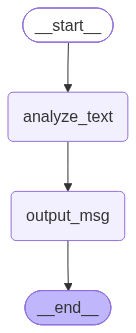

{'output': 'Input is long'}


In [12]:
from typing import TypedDict
from langgraph.graph import StateGraph, START, END
from IPython.display import Image, display

## Input Schema
class InputState(TypedDict):
    input: str
    
## Global Schema
class GlobalState(TypedDict):
    character_count: int
    word_count: int

## Output Schema
class OutputState(TypedDict):
    output: str


## Node 1 - Calculates Word and Character counts
def analyze_text(state: InputState) -> GlobalState:
    character_count = len(state["input"])
    word_count = len(state["input"].split())
    return {"character_count": character_count, "word_count": word_count}


## Node 2 - Produce output message
def output_msg(state: GlobalState) -> OutputState:
    if (state["character_count"] > 20) or (state["word_count"] > 3):
        output = "Input is long"
    else:
        output = "Input is short"
    return {"output": output}


## Initialize StateGraph with state, input, and output schema
builder = StateGraph(state_schema=GlobalState,
                     input_schema=InputState,
                     output_schema=OutputState)

## Add Nodes
builder.add_node("analyze_text", analyze_text)
builder.add_node("output_msg", output_msg)

## Add Edges
builder.add_edge(START, "analyze_text")
builder.add_edge("analyze_text", "output_msg")
builder.add_edge("output_msg", END)

## Compile graph
graph = builder.compile()

## Visualize graph
display(Image(graph.get_graph().draw_mermaid_png()))

## Invoke Graph 
print(graph.invoke({"input": "Hello World, How Are You?"}))


### Private Schema

#### Example

In [13]:
from typing import TypedDict
from langgraph.graph import StateGraph, START, END
from IPython.display import Image, display


## Global schemas
class GlobalState(TypedDict):
    input: str
    output: str

class PrivateState(TypedDict):
    character_count: int
    word_count: int


## Node 1 - Analyze input text
def analyze_text(state: GlobalState) -> PrivateState:
    character_count = len(state["input"])
    word_count = len(state["input"].split())
    return {"character_count": character_count, "word_count": word_count}


## Node 2 - Produce output message
def output_msg(state: PrivateState) -> GlobalState:
    if (state["character_count"] > 20) or (state["word_count"] > 3):
        output = "Input is long"
    else:
        output = "Input is short"
    return {"output": output}


## Build graph
builder = StateGraph(state_schema=GlobalState)

builder.add_node("analyze_text", analyze_text)
builder.add_node("output_msg", output_msg)

builder.add_edge(START, "analyze_text")
builder.add_edge("analyze_text", "output_msg")
builder.add_edge("output_msg", END)

## Compile graph
graph = builder.compile()

## Visualize graph (optional)
#display(Image(graph.get_graph().draw_mermaid_png()))

## Invoke Graph 
print(graph.invoke({"input": "Hello World!"}))


{'input': 'Hello World!', 'output': 'Input is short'}


### Reducers

#### Overwrite Values

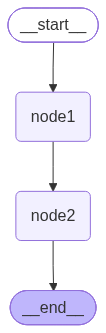

{'counter': 2}


In [14]:
from typing import TypedDict
from langgraph.graph import StateGraph
from IPython.display import Image, display

## Define state
class GraphState(TypedDict):
    counter: int

## Define Node Functions
def node1(state: GraphState): 
    """Node 1: set counter as 1"""
    state["counter"] = 1
    return state

def node2(state: GraphState): 
    """Node 2: set counter as 2"""
    state["counter"] = 2
    return state

## Initialize StateGraph
graph_builder = StateGraph(GraphState)

## Add Nodes
graph_builder.add_node("node1", node1)
graph_builder.add_node("node2", node2)

## Connect Node1 to Node2
graph_builder.add_edge("node1", "node2")

## Set the entry point of the graph
graph_builder.set_entry_point("node1")

## Compile Graph
graph = graph_builder.compile()

## Visualize Graph 
display(Image(graph.get_graph().draw_mermaid_png()))

## Invoke Graph with empty dictionary
print(graph.invoke({}))


#### Add Values (Numerical)

In [15]:
from typing import TypedDict, Annotated
from langgraph.graph import StateGraph
from IPython.display import Image, display
from operator import add

## Define state
class GraphState(TypedDict):
    counter:Annotated[int, add] # Use 'add' as reducer

## Define Node Functions
def node1(state: GraphState): 
    """Node 1: set counter as 1"""
    state["counter"] = 1
    return state

def node2(state: GraphState): 
    """Node 2: set counter as 2"""
    state["counter"] = 2
    return state

## Initialize StateGraph
graph_builder = StateGraph(GraphState)

## Add Nodes
graph_builder.add_node("node1", node1)
graph_builder.add_node("node2", node2)

## Connect Node1 to Node2
graph_builder.add_edge("node1", "node2")

## Set the entry point of the graph
graph_builder.set_entry_point("node1")

## Compile Graph
graph = graph_builder.compile()

## Visualize Graph (optional)
#display(Image(graph.get_graph().draw_mermaid_png()))

## Invoke Graph with empty dictionary
print(graph.invoke({}))


{'counter': 3}


#### Append Values in List

In [16]:
from typing import TypedDict, Annotated
from langgraph.graph import StateGraph
from IPython.display import Image, display
from operator import add

## Define state
class GraphState(TypedDict):
    counter: Annotated[list[int], add] # Use 'add' as reducer

## Define Node Functions
def node1(state: GraphState): 
    """Node 1: set counter as [1]"""
    state["counter"] = [1]
    return state

def node2(state: GraphState): 
    """Node 2: set counter as [2]"""
    state["counter"] = [2]
    return state

## Initialize StateGraph
graph_builder = StateGraph(GraphState)

## Add Nodes
graph_builder.add_node("node1", node1)
graph_builder.add_node("node2", node2)

## Connect Node1 to Node2
graph_builder.add_edge("node1", "node2")

## Set the entry point of the graph
graph_builder.set_entry_point("node1")

## Compile Graph
graph = graph_builder.compile()

## Visualize Graph (optional)
#display(Image(graph.get_graph().draw_mermaid_png()))

## Invoke Graph with empty dictionary
print(graph.invoke({}))


{'counter': [1, 2]}


#### Custom Reducers

In [17]:
from typing import TypedDict, Annotated
from langgraph.graph import StateGraph
from IPython.display import Image, display

def merge_unique(existing: list, new: list) -> list:
    """Only add items if they are not in the list already"""
    result = existing.copy()
    for item in new:
        if item not in result:
            result.append(item)
    return result

# Define state
class GraphState(TypedDict):
    counter: Annotated[list[int], merge_unique] # Use custom reducer

## Define Node Functions
def node1(state: GraphState): 
    """Node 1: set counter as [1,2]"""
    state["counter"] = [1,2]
    return state

def node2(state: GraphState): 
    """Node 2: set counter as [2,3]"""
    state["counter"] = [2,3]
    return state

## Initialize StateGraph
graph_builder = StateGraph(GraphState)

## Add Nodes
graph_builder.add_node("node1", node1)
graph_builder.add_node("node2", node2)

## Connect Node1 to Node2
graph_builder.add_edge("node1", "node2")

## Set the entry point of the graph
graph_builder.set_entry_point("node1")

## Compile Graph
graph = graph_builder.compile()

## Visualize Graph (optional)
#display(Image(graph.get_graph().draw_mermaid_png()))

## Invoke Graph with empty dictionary
print(graph.invoke({}))


{'counter': [1, 2, 3]}


## <font color="#3366FF">Built-in Message State</font>

### Add Message Reducer

In [18]:
from langgraph.graph.message import add_messages
from langchain.messages import AIMessage, HumanMessage

# Existing message list
existing_messages = [AIMessage(content="Hello! How can I help you?"),
                    HumanMessage(content="Can you help me in Python programming?")
                   ]

# New message to add
new_message = AIMessage(content="Sure, please tell me what exact help you need in Python programming?", name="Model")

# Call add_message reducer function
add_messages(existing_messages , new_message)


[AIMessage(content='Hello! How can I help you?', additional_kwargs={}, response_metadata={}, id='772aad06-5b07-4f4a-96a8-eb4063c222c7', tool_calls=[], invalid_tool_calls=[]),
 HumanMessage(content='Can you help me in Python programming?', additional_kwargs={}, response_metadata={}, id='4b183b5e-dc76-49a2-8682-f6f124c8508b'),
 AIMessage(content='Sure, please tell me what exact help you need in Python programming?', additional_kwargs={}, response_metadata={}, name='Model', id='ddab716e-aa2c-4bf9-995c-34fd005aacf6', tool_calls=[], invalid_tool_calls=[])]

### Messages State (Built-In)

### Example

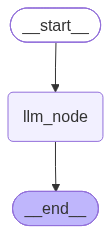


--- Conversation ---
================================ Human Message =================================

Hi! Can you tell me a fun fact about birds in one line
================================== Ai Message ==================================

Hi Ankur — fun fact: hummingbirds are the only birds that can fly backwards, thanks to their unique figure-eight wing strokes.


In [19]:
import os
from dotenv import load_dotenv
from typing import TypedDict, Annotated
from langchain.messages import HumanMessage, AIMessage
from langgraph.graph import StateGraph, START, END, MessagesState
from langchain_openai import ChatOpenAI
from IPython.display import Image, display

## Loading OpenAI API key from env file into an environment variable
load_dotenv()
os.environ["OPENAI_API_KEY"] = os.getenv('OPENAI_API_KEY')

## Define OpenAI Chat Model
llm = ChatOpenAI(model="gpt-5-mini")


## Define state with MessagesState
class ChatMessageState(MessagesState):
    user_name: str     


## Define llm node function
def llm_node(state: ChatMessageState):
    
    prompt = [
        HumanMessage(content=f"Give personalize response to User {state['user_name']} question: {state['messages'][-1].content}")
    ]
    
    response = llm.invoke(prompt)
    
    return {"messages": [response]}


## Initialize StateGraph
graph_builder = StateGraph(ChatMessageState)

## Add node
graph_builder.add_node("llm_node", llm_node)

## Add edges
graph_builder.add_edge(START, "llm_node")
graph_builder.add_edge("llm_node", END)

## Compile graph
graph = graph_builder.compile()

## Visualize Graph
display(Image(graph.get_graph().draw_mermaid_png()))

## Initial state (chat starts here)
initial_state = {
    "messages": [HumanMessage(content="Hi! Can you tell me a fun fact about birds in one line")],
    "user_name": "Ankur"
}

## Invoke Graph
final_state = graph.invoke(initial_state)


## Print Conversation
print("\n--- Conversation ---")
for msg in final_state["messages"]:
    msg.pretty_print()


# <font color="#800000">Subgraph</font>

## <font color="#3366FF">Call Subgraph From Parent Graph Node</font>

### Example

#### Create IT Subgraph

IT Subgraph Visualization:



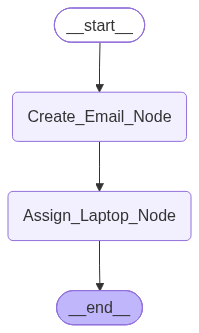

In [20]:
from typing import List, TypedDict
from langgraph.graph import StateGraph, START, END
from IPython.display import Image, display


## -------- SUB GRAPH (IT) -------------------


## Define TypedDict for IT subgraph state
class ITState(TypedDict):
    new_hire_name: str
    assets: List[str]


## Node function to create email
def create_email(state: ITState):
    email = f"{state['new_hire_name'].lower().replace(' ', '.')}@company.com"
    ## Return state by assigning the new email to assets
    state["assets"] = state.get("assets", []) + [email]
    return state


## Node function to assign laptop
def assign_laptop(state: ITState):
    ## Return state by appending the laptop to assets
    state["assets"] = state.get("assets", []) + ["MacBook Pro"]
    return state


## Initialize the StateGraph with TypedDict for IT Subgraph
it_builder = StateGraph(ITState)

## Add nodes
it_builder.add_node("Create_Email_Node", create_email)
it_builder.add_node("Assign_Laptop_Node", assign_laptop)

## Add edge from START to Create_Email_Node
it_builder.add_edge(START, "Create_Email_Node")

## Add edge from Create_Email_Node to Assign_Laptop_Node
it_builder.add_edge("Create_Email_Node", "Assign_Laptop_Node")

## Add edge from Assign_Laptop_Node to END
it_builder.add_edge("Assign_Laptop_Node", END)

## Compile the IT subgraph
it_subgraph = it_builder.compile()

## Visualize Graph
print("IT Subgraph Visualization:\n")
display(Image(it_subgraph.get_graph().draw_mermaid_png()))


#### Create Parent HR Graph


HR Graph Visualization:



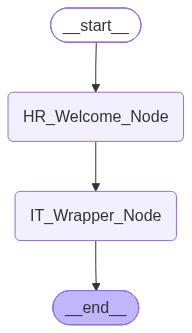

In [21]:
## -------- PARENT GRAPH (HR) -------------------

## Define TypedDict for HR parent graph state
class HRState(TypedDict):
    employee_name: str
    hr_status: str


## Node function for HR welcome
def hr_welcome(state: HRState):
    state["hr_status"] = f"HR Notes: Welcome package sent to {state['employee_name']} from HR."
    return state


## Node function for wrapping the IT subgraph
def call_it_department(state: HRState):
    ## Map parent state to subgraph state
    it_input = {"new_hire_name": state["employee_name"], "assets": []}
    
    ## Invoke the subgraph
    it_output = it_subgraph.invoke(it_input)
    
    ## Map subgraph state back to parent state
    assets_str = ", ".join(it_output["assets"])
    state["hr_status"] = f"{state.get('hr_status', '')} \nIT Notes: {assets_str} assigned."
    return state


## Initialize the StateGraph with TypedDict for HR Parent Graph
hr_builder = StateGraph(HRState)

## Add nodes
hr_builder.add_node("HR_Welcome_Node", hr_welcome)
hr_builder.add_node("IT_Wrapper_Node", call_it_department)

## Add edge from START to HR_Welcome_Node
hr_builder.add_edge(START, "HR_Welcome_Node")

## Add edge from HR_Welcome_Node to IT_Wrapper_Node
hr_builder.add_edge("HR_Welcome_Node", "IT_Wrapper_Node")

## Add edge from IT_Wrapper_Node to END
hr_builder.add_edge("IT_Wrapper_Node", END)

## Compile the parent graph
parent_graph = hr_builder.compile()

## Visualize Graph
print("\nHR Graph Visualization:\n")
display(Image(parent_graph.get_graph().draw_mermaid_png()))


#### Invoke Parent HR Graph

In [22]:
## Invoke Parent Graph
result = parent_graph.invoke({"employee_name": "Alice Smith"})
print(result["hr_status"])


HR Notes: Welcome package sent to Alice Smith from HR. 
IT Notes: alice.smith@company.com, MacBook Pro assigned.


## <font color="#3366FF">Add Subgraph As Node In Parent Graph</font>

### Example

#### Define Common State Schema

In [23]:
from typing import TypedDict
from langgraph.graph import StateGraph, START, END
from IPython.display import Image, display


## Define TypedDict for shared company state
class CompanyState(TypedDict):
    employee_name: str
    hr_notes: str
    it_notes: str


#### Create IT Subgraph

IT Subgraph Visualization:



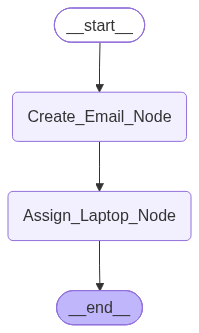

In [24]:
## -------- SUB GRAPH (IT) -------------------

## Node function to create email
def create_email(state: CompanyState):
    email = f"{state['employee_name'].lower().replace(' ', '.')}@company.com"
    state["it_notes"] = f"Email created: {email}."
    return state


## Node function to assign laptop
def assign_laptop(state: CompanyState):
    current_notes = state.get("it_notes", "")
    state["it_notes"] = f"{current_notes} MacBook Pro assigned."
    return state


## Initialize the StateGraph with TypedDict for IT Subgraph
it_builder = StateGraph(CompanyState)

## Add nodes
it_builder.add_node("Create_Email_Node", create_email)
it_builder.add_node("Assign_Laptop_Node", assign_laptop)

## Add edge from START to Create_Email_Node
it_builder.add_edge(START, "Create_Email_Node")

## Add edge from Create_Email_Node to Assign_Laptop_Node
it_builder.add_edge("Create_Email_Node", "Assign_Laptop_Node")

## Add edge from Assign_Laptop_Node to END
it_builder.add_edge("Assign_Laptop_Node", END)

## Compile the IT subgraph
it_subgraph = it_builder.compile()

## Visualize Graph
print("IT Subgraph Visualization:\n")
display(Image(it_subgraph.get_graph().draw_mermaid_png()))


#### Create HR Parent Graph


HR Graph Visualization:



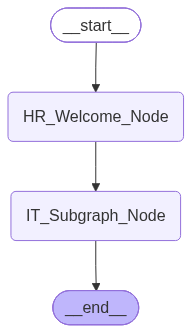

In [25]:
## -------- PARENT GRAPH (HR) -------------------

## Node function for HR welcome
def hr_welcome(state: CompanyState):
    state["hr_notes"] = f"Welcome package sent to {state['employee_name']}."
    return state


## Initialize the StateGraph with TypedDict for HR Parent Graph
hr_builder = StateGraph(CompanyState)

## Add nodes (passing the compiled subgraph directly as a node)
hr_builder.add_node("HR_Welcome_Node", hr_welcome)
hr_builder.add_node("IT_Subgraph_Node", it_subgraph)

## Add edge from START to HR_Welcome_Node
hr_builder.add_edge(START, "HR_Welcome_Node")

## Add edge from HR_Welcome_Node to IT_Subgraph_Node
hr_builder.add_edge("HR_Welcome_Node", "IT_Subgraph_Node")

## Add edge from IT_Subgraph_Node to END
hr_builder.add_edge("IT_Subgraph_Node", END)

## Compile the parent graph
parent_graph = hr_builder.compile()

## Visualize Graph
print("\nHR Graph Visualization:\n")
display(Image(parent_graph.get_graph().draw_mermaid_png()))


#### Invoke Parent HR Graph

In [26]:
## Test the workflow
result = parent_graph.invoke({"employee_name": "Bob Jones"})
print("HR Notes:", result["hr_notes"])
print("IT Notes:", result["it_notes"])


HR Notes: Welcome package sent to Bob Jones.
IT Notes: Email created: bob.jones@company.com. MacBook Pro assigned.
